# Platelet study: multiple single-cell foundation models

The historical platelet study evaluated **STATE, UCE, TranscriptFormer, Geneformer, scPRINT-2, STACK, and scGPT**. This notebook makes those existing results visible together.

| Section | Material | What is reproduced here |
|---|---|---|
| A — Study inventory and historical metrics | Archived results for 7 scFMs and PCA baselines | Source checks and recorded tables; no model training |
| B — Five-model UMAP gallery | Stored coordinates for STATE, UCE, TranscriptFormer, Geneformer and scPRINT-2 | A common-cell display with consistent annotation colors |
| C — Optional software walkthrough | 320 synthetic cells from 40 synthetic donors | The current portable donor-aware evaluator |

The archives predate the QC rebuild. We keep their populations and metric definitions visible rather than presenting them as a newly validated ranking. STACK and scGPT have recorded benchmark results; their matching UMAP files are not present in the selected visualization archive.

**Run:** choose **Restart Kernel and Run All Cells**. No GPU, model weights, or data download is needed after setup. Research source files are read only.


## 1. Setup

From the repository root, install into the Python environment used by your kernel:

```bash
python -m pip install . jupyterlab
jupyter lab examples/platelet/platelet_case_demo.ipynb
```

Keep the checkout's directory structure. The notebook works from the repository root or its own directory. Project maintainers follow the [HPCC execution rules](../../DEVELOPMENT.md). Numerical evaluation is reused from the package; the cells below add the study walkthrough and visualization.


In [1]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Image, display

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "examples/platelet/platelet_case_demo.ipynb").is_file()),
    None,
)
assert ROOT is not None, "Run this notebook from inside the scfm-benchmark checkout."
sys.path.insert(0, str(ROOT / "src"))
from scfm_benchmark.demo import make_demo_data
from scfm_benchmark.benchmark import evaluate_embeddings

STAGE = ROOT / "scripts/24_option_c_canonical_input"
MODEL_NAMES = {
    "state": "STATE", "uce": "UCE", "transcriptformer": "TranscriptFormer",
    "geneformer": "Geneformer", "scprint2": "scPRINT-2",
}
ALL_MODELS = [*MODEL_NAMES.values(), "STACK", "scGPT"]
print("Ready: seven-model archive, five-model visualization, optional synthetic evaluator.")


Ready: seven-model archive, five-model visualization, optional synthetic evaluator.


## 2. Part A — Verify the archived study inputs

Use the existing [stage manifest](../../scripts/24_option_c_canonical_input/results/manifest.json) to verify each file before reading it. This manifest was reconstructed during an earlier audit; its checksums identify the archived files, not proof that every historical scientific conclusion is current.

The visualization archive and the disease-matched benchmark archive contain different populations. We retain their cell counts separately.


In [2]:
manifest_path = STAGE / "results/manifest.json"
manifest = json.loads(manifest_path.read_text())
declared_files = {item["path"]: item for item in manifest["outputs"]}
source_hashes = {"results/manifest.json": hashlib.sha256(manifest_path.read_bytes()).hexdigest()}

def checked_path(relative):
    path = STAGE / relative
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == declared_files[relative]["sha256"], f"Checksum mismatch: {relative}"
    source_hashes[relative] = digest
    return path

coordinate_frames = {}
model_summaries = {}
for key, name in MODEL_NAMES.items():
    coordinate_file = checked_path(f"results/option_c_bio_interpretation/umap_{key}.csv")
    summary_file = checked_path(f"results/option_c_bio_interpretation/summary_{key}.json")
    summary = json.loads(summary_file.read_text())
    frame = pd.read_csv(
        coordinate_file, usecols=["Cell_ID", "UMAP1", "UMAP2", "cohort", "severity"],
        dtype={"Cell_ID": str, "cohort": str, "severity": str},
    )
    assert summary["model"] == key
    assert len(frame) == summary["n_cells_total"] and len(frame) > 0
    assert frame.Cell_ID.is_unique and not frame.isna().any().any()
    assert np.isfinite(frame[["UMAP1", "UMAP2"]].to_numpy()).all()
    coordinate_frames[name] = frame.set_index("Cell_ID", verify_integrity=True)
    model_summaries[name] = summary

benchmark_relative = "results/option_c_primary_benchmark/covid_sepsis_only/mortality_lr_rf.csv"
pca_relative = "results/option_c_primary_benchmark/covid_sepsis_only/pca_baseline.csv"
historical_metrics = pd.read_csv(checked_path(benchmark_relative))
historical_pca = pd.read_csv(checked_path(pca_relative))
assert set(historical_metrics.fm) == set(ALL_MODELS)
assert not historical_metrics.duplicated(["fm", "classifier"]).any()
assert set(historical_metrics.classifier) == {"LR", "RF"}
assert len(historical_metrics) == 14
assert historical_metrics.auc_mean.between(0, 1).all()
assert historical_pca.auc_mean.between(0, 1).all()
print(f"Verified {len(source_hashes) - 1} archived input files against the stage manifest.")


Verified 12 archived input files against the stage manifest.


In [3]:
inventory = historical_metrics.query("classifier == 'LR'").set_index("fm")[
    ["n_cells", "n_donors"]
].reindex(ALL_MODELS).rename(columns={
    "n_cells": "historical_benchmark_cells",
    "n_donors": "reported_groups_as_n_donors",
})
inventory["stored_umap_cells"] = pd.Series({name: len(frame) for name, frame in coordinate_frames.items()})
inventory["embedding_dimensions"] = pd.Series({
    name: summary["embedding_dim"] for name, summary in model_summaries.items()
})
inventory["umap_available_in_this_archive"] = inventory.index.isin(coordinate_frames)
display(inventory.astype({
    "stored_umap_cells": "Int64", "embedding_dimensions": "Int64",
}))


,historical_benchmark_cells,reported_groups_as_n_donors,stored_umap_cells,embedding_dimensions,umap_available_in_this_archive
fm,,,,,
STATE,42095,322,44603,2058,True
UCE,42095,322,44603,1280,True
TranscriptFormer,41315,322,43798,2048,True
Geneformer,41320,322,43803,1152,True
scPRINT-2,41320,322,43803,424,True
STACK,42095,322,<NA>,<NA>,False
scGPT,42095,322,<NA>,<NA>,False


## 3. Read the existing multi-model results

The next two tables are **archived results**, read from the disease-matched `covid_sepsis_only` directory. They are not newly fitted models or outputs of this notebook's synthetic demonstration.

Keep `n_cells` and the archive's `n_donors` field alongside the AUCs. The latter is reproduced as recorded, not a fresh validation of donor identity. The historical [benchmark code](../../scripts/24_option_c_canonical_input/code/primary_benchmark_option_c.py) groups folds by `Sample_ID` and scores held-out cells; this differs from the current portable evaluator's averaging of probabilities within verified donors. The exact historical runs were not independently rerun here.

`auc_mean` and `auc_std` retain their original meanings; fold SD is not a confidence interval. Different model cell counts, upstream processing, dependency mapping and the later QC rebuild prevent treating these archived rows as a new fair-comparison leaderboard. The [PCA recipe](../../scripts/24_option_c_canonical_input/code/pca_baseline_mortality.py) and its archived table are shown separately, without adding a winner claim.


In [4]:
print("ARCHIVED scFM RESULTS — original fields, no reranking")
display(historical_metrics[
    ["fm", "classifier", "n_cells", "n_donors", "auc_mean", "auc_std"]
].round({"auc_mean": 4, "auc_std": 4}))
print("ARCHIVED PCA BASELINES — same result directory, separate table")
display(historical_pca.round({"auc_mean": 4, "auc_std": 4}))


ARCHIVED scFM RESULTS — original fields, no reranking


,fm,classifier,n_cells,n_donors,auc_mean,auc_std
0,STATE,LR,42095,322,0.7236,0.1062
1,STATE,RF,42095,322,0.6648,0.1135
2,UCE,LR,42095,322,0.5980,0.1408
3,UCE,RF,42095,322,0.6020,0.1603
4,TranscriptFormer,LR,41315,322,0.7192,0.0898
5,TranscriptFormer,RF,41315,322,0.6408,0.1292
6,scPRINT-2,LR,41320,322,0.7618,0.1349
7,scPRINT-2,RF,41320,322,0.7218,0.1465
8,STACK,LR,42095,322,0.5620,0.1807
9,STACK,RF,42095,322,0.6430,0.1102


ARCHIVED PCA BASELINES — same result directory, separate table


,method,n_components,auc_mean,auc_std,fold_aucs
0,PCA-50+LR,50,0.7059,0.0939,0.683;0.830;0.701;0.766;0.550
1,PCA-100+LR,100,0.7016,0.0759,0.701;0.750;0.721;0.777;0.559
2,PCA-200+LR,200,0.7052,0.0710,0.716;0.753;0.683;0.791;0.583
3,PCA-500+LR,500,0.7034,0.0656,0.724;0.736;0.663;0.792;0.601


## 4. Part B — Match cell identities for the five available projections

The five visualization files contain different cell counts. For the gallery only, intersect **cell IDs**, keep their stored coordinates, and verify that cohort and severity annotations agree for every shared cell.

This is a display subset; no research input is changed or excluded from its original analysis. Each projection was originally fitted on its own population. Subsetting the plotted points does not refit UMAP or make those original fits identical.


In [5]:
common_ids = sorted(set.intersection(*(set(frame.index) for frame in coordinate_frames.values())))
assert common_ids, "No shared cells across the five projections."
reference_labels = coordinate_frames["STATE"].loc[common_ids, ["cohort", "severity"]]
for name, frame in coordinate_frames.items():
    pd.testing.assert_frame_equal(
        frame.loc[common_ids, ["cohort", "severity"]], reference_labels,
        obj=f"{name} shared-cell annotations",
    )
coverage = pd.DataFrame({
    "stored_cells": {name: len(frame) for name, frame in coordinate_frames.items()},
    "displayed_common_cells": len(common_ids),
})
coverage["not_shown_in_common_cell_gallery"] = coverage.stored_cells - len(common_ids)
display(coverage)
print(f"{len(common_ids):,} shared cell IDs with matching annotations.")


,stored_cells,displayed_common_cells,not_shown_in_common_cell_gallery
STATE,44603,43798,805
UCE,44603,43798,805
TranscriptFormer,43798,43798,0
Geneformer,43803,43798,5
scPRINT-2,43803,43798,5


43,798 shared cell IDs with matching annotations.


### Inspect the shared-cell annotations

These are **cell counts**, not donor counts. The stored field `severity` mixes severity terms with outcome-like strings (`fatal`, `recovered`); the original strings are kept without defining a new clinical endpoint.


In [6]:
cell_counts = pd.crosstab(reference_labels["cohort"], reference_labels["severity"])
display(cell_counts)
assert int(cell_counts.to_numpy().sum()) == len(common_ids)


severity,fatal,mild,moderate,recovered,severe
cohort,,,,,
302004data01,0,24,0,0,155
302004data02,0,287,0,0,690
302004data04,106,109,0,0,401
302004data05,0,0,612,0,3860
302004data15,2144,997,0,0,5253
302004data16,117,1847,0,0,36
302004data17,2271,2322,3349,0,4158
302004data18,0,0,0,0,471
302005data01,998,0,312,3348,752


## 5. Five models, two annotation views

Columns are models; rows are source cohort and recorded severity. Every panel uses the same shared cell IDs and drawing order. Colors are fixed across models. Within each model, both views use identical coordinates and axis scales.

Axes remain independent **between models** because UMAP axes, orientation and distances are not a common embedding coordinate system. Cluster shape or visual separation alone is not a performance measure. STACK and scGPT are represented in the result tables above; this gallery does not imply that they were never run.


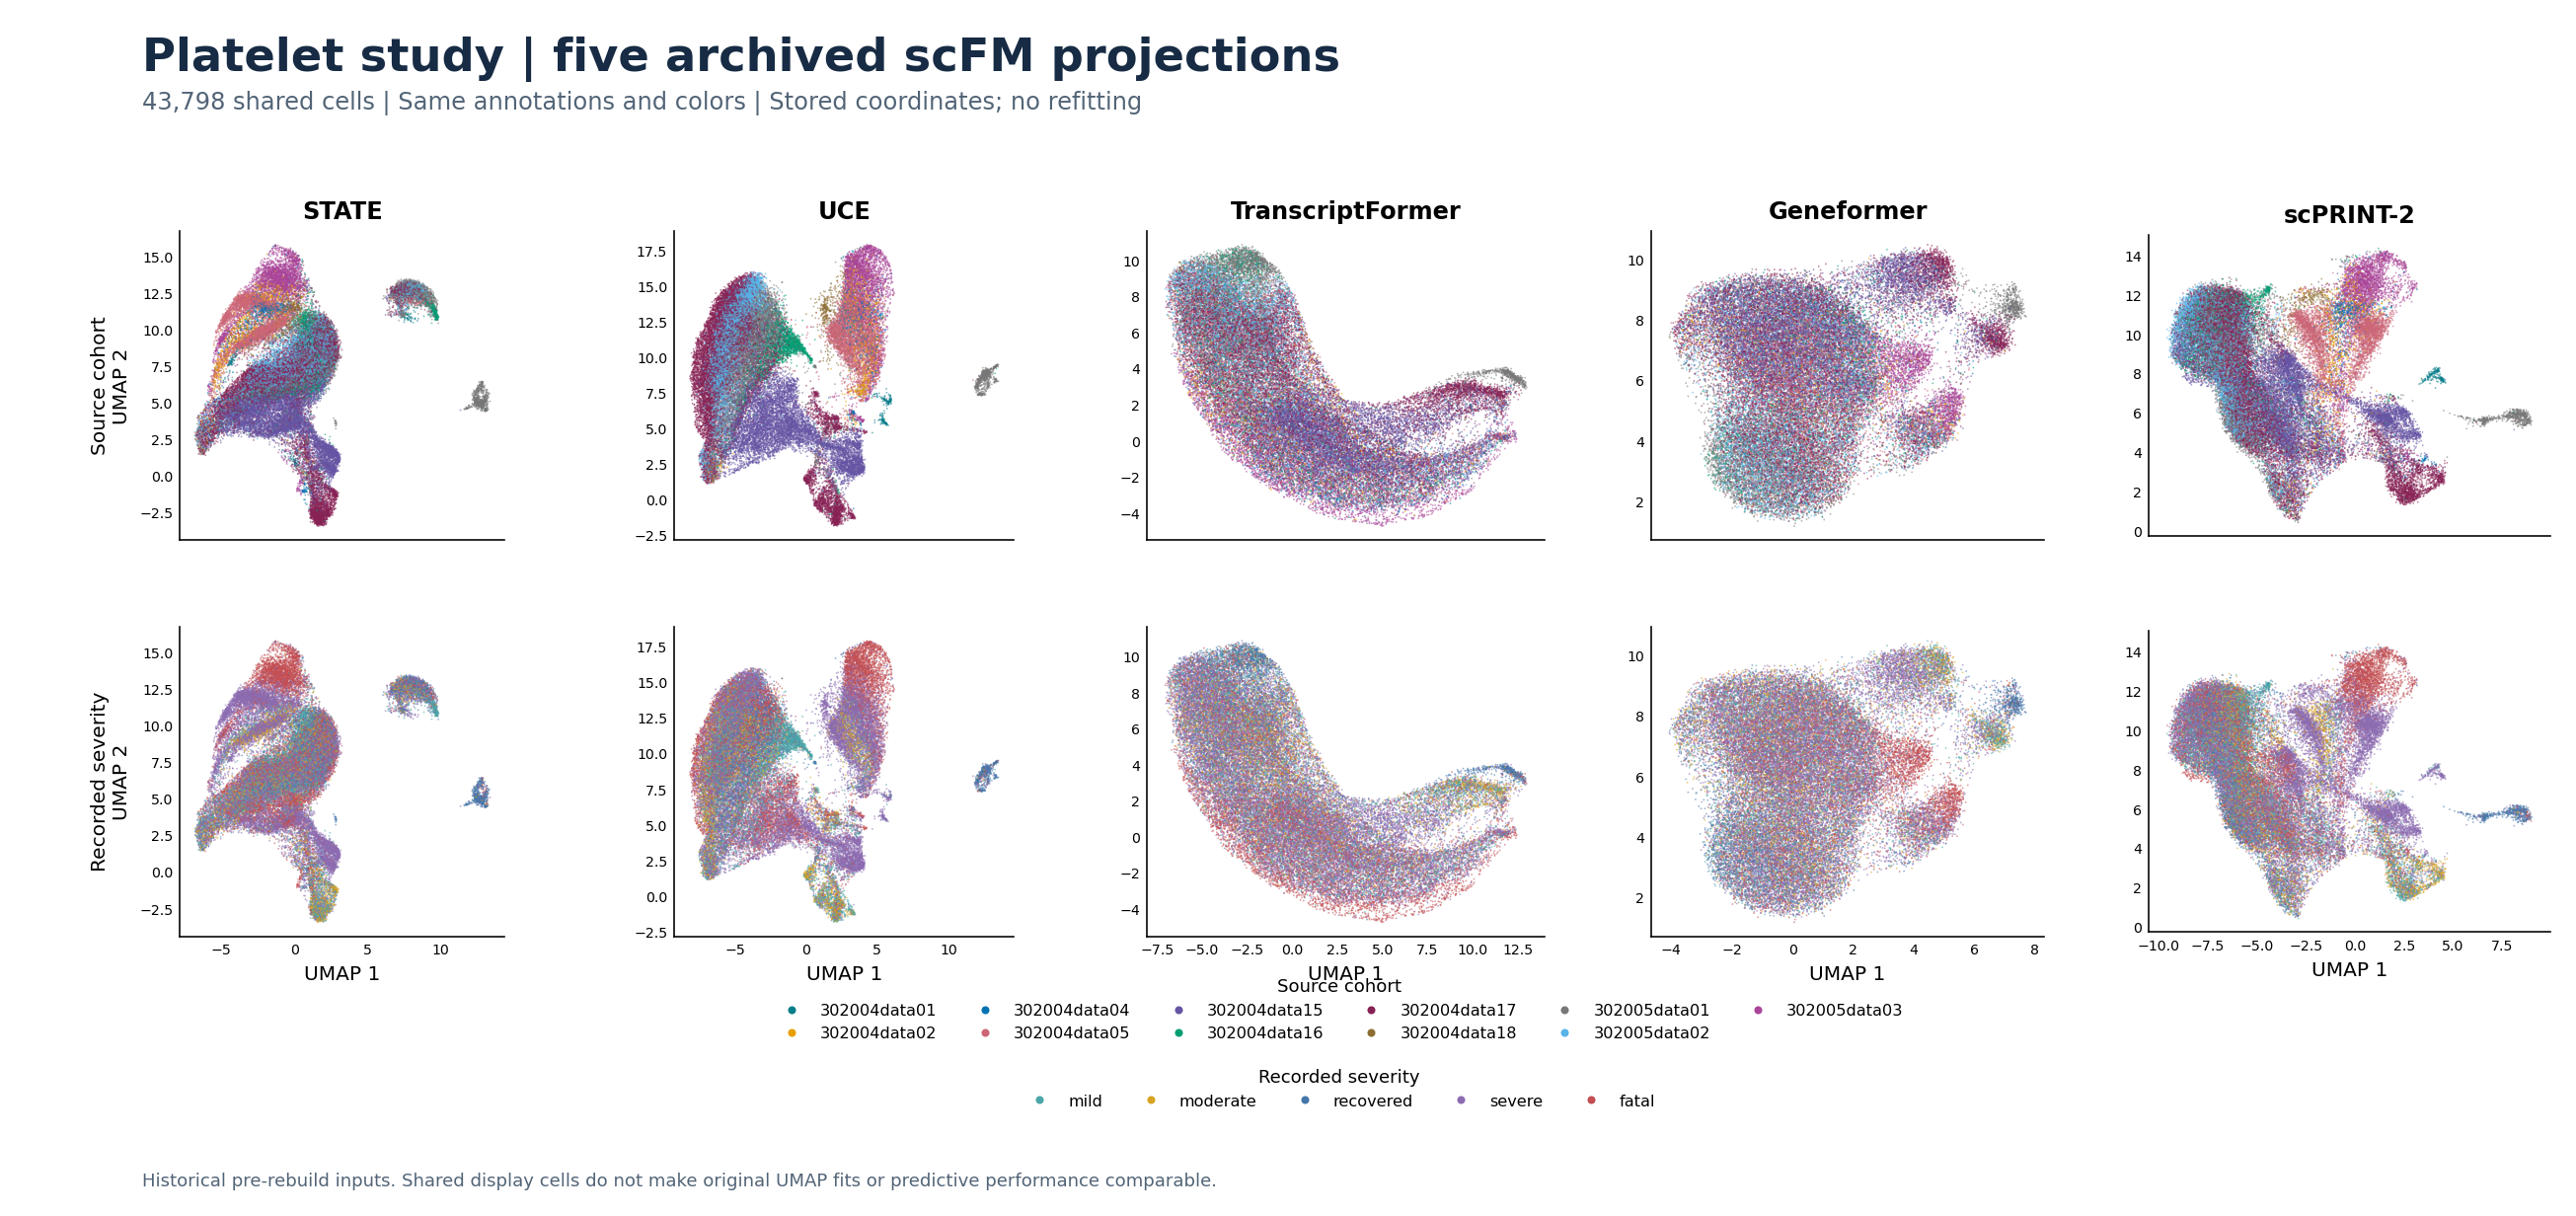

In [7]:
cohort_colors = ["#087E8B", "#E69F00", "#0072B2", "#CC6677", "#6654A4",
                 "#009E73", "#882255", "#8C6D31", "#777777", "#56B4E9", "#AA4499"]
cohorts = sorted(reference_labels.cohort.unique())
assert len(cohorts) <= len(cohort_colors)
cohort_palette = dict(zip(cohorts, cohort_colors))
severity_palette = {"mild": "#4AA6A8", "moderate": "#D8A323", "recovered": "#4477AA",
                    "severe": "#8C6BB1", "fatal": "#C44E52"}
assert set(reference_labels.severity) <= set(severity_palette)
palettes = {"cohort": cohort_palette, "severity": severity_palette}
draw_ids = np.asarray(common_ids)[np.random.default_rng(42).permutation(len(common_ids))]

fig, axes = plt.subplots(2, 5, figsize=(18, 8.5), sharex="col", sharey="col")
fig.subplots_adjust(left=0.055, right=0.99, top=0.81, bottom=0.23, wspace=0.25, hspace=0.28)
fig.suptitle("Platelet study | five archived scFM projections", x=0.055, y=0.97,
             ha="left", fontsize=23, weight="bold", color="#172B44")
fig.text(0.055, 0.91, f"{len(common_ids):,} shared cells | Same annotations and colors | Stored coordinates; no refitting",
         fontsize=12, color="#526477")
for column, (name, frame) in enumerate(coordinate_frames.items()):
    points = frame.loc[draw_ids]
    for row, annotation in enumerate(("cohort", "severity")):
        ax = axes[row, column]
        ax.scatter(points.UMAP1, points.UMAP2,
                   c=points[annotation].map(palettes[annotation]),
                   s=0.8, alpha=0.55, linewidths=0, rasterized=True)
        if row == 0:
            ax.set_title(name, fontsize=12, weight="bold")
        if column == 0:
            ax.set_ylabel("Source cohort\nUMAP 2" if row == 0 else "Recorded severity\nUMAP 2")
        if row == 1:
            ax.set_xlabel("UMAP 1")
        ax.set_aspect("equal", adjustable="box")
        ax.tick_params(labelsize=7, length=0)
        ax.spines[["top", "right"]].set_visible(False)
for annotation, y in [("cohort", 0.17), ("severity", 0.105)]:
    palette = palettes[annotation]
    handles = [Line2D([], [], linestyle="", marker="o", markersize=4,
                      markeredgewidth=0, color=color, label=label)
               for label, color in palette.items()]
    fig.legend(handles=handles, loc="center", bbox_to_anchor=(0.52, y),
               ncol=6, frameon=False, fontsize=8,
               title="Source cohort" if annotation == "cohort" else "Recorded severity",
               title_fontsize=9)
fig.text(0.055, 0.025,
         "Historical pre-rebuild inputs. Shared display cells do not make original UMAP fits or predictive performance comparable.",
         fontsize=9, color="#526477")
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=145)
plt.close(fig)
display(Image(data=buffer.getvalue(), width=1200))


## 6. Part C — Optional: run the current evaluator on synthetic inputs

The real study results above are already archived. This final exercise separately demonstrates the current portable evaluation software.

The existing generator produces 40 donors, eight cells per donor, and 20 dependency groups. `toy_signal`, `toy_noise` and `toy_expression_pca` are artificial feature matrices, not real scFM outputs or raw gene counts. No platelet coordinate or clinical label enters this fit.


In [8]:
synthetic_metadata, synthetic_embeddings = make_demo_data()
assert len(synthetic_metadata) == 320
assert synthetic_metadata.donor_id.nunique() == 40
assert synthetic_metadata.cv_group.nunique() == 20
display(pd.DataFrame([
    {"representation": name, "cells": len(frame), "features": frame.shape[1] - 1}
    for name, frame in synthetic_embeddings.items()
]))


,representation,cells,features
0,toy_signal,320,12
1,toy_noise,320,12
2,toy_expression_pca,320,30


Scaling, optional PCA and logistic regression are fitted on training cells only. All representations reuse dependency-group folds; predictions are averaged within each held-out donor. Training weights cells equally, while reported metrics weight donors equally. `prior` is the training-cell class-prevalence baseline.


In [9]:
synthetic_results = evaluate_embeddings(
    synthetic_metadata, synthetic_embeddings,
    n_splits=5, seeds=(42, 43, 44), pca={"toy_expression_pca": 5},
)
synthetic_metrics = synthetic_results["metrics"]
synthetic_predictions = synthetic_results["predictions"]
synthetic_folds = synthetic_results["folds"]
assert len(synthetic_predictions) == 40 * 4 * 3
assert not synthetic_predictions.duplicated(["seed", "model", "donor_id"]).any()
assert (synthetic_folds.groupby(["seed", "cv_group"]).fold.nunique() == 1).all()
assert (synthetic_predictions.groupby(["seed", "donor_id"]).fold.nunique() == 1).all()
assert (synthetic_metrics["n_donors"] == 40).all()
assert len(synthetic_metrics) == 4 * 3
print("SYNTHETIC DATA — mean donor-level metrics across three seeds")
display(synthetic_metrics.groupby("model")[
    ["roc_auc", "average_precision", "brier_score"]
].mean().round(4))


SYNTHETIC DATA — mean donor-level metrics across three seeds


,roc_auc,average_precision,brier_score
model,,,
prior,0.5000,0.5000,0.2500
toy_expression_pca,0.5875,0.5708,0.2505
toy_noise,0.3575,0.4423,0.2649
toy_signal,0.7500,0.7038,0.2085


AUROC and average precision are higher-is-better; Brier score is lower-is-better. These synthetic scores illustrate mechanics and do not rank the seven real models above. Repeats reuse the same donors and are not independent cohorts; split variability is not a confidence interval.

Inspect per-repeat metrics, dependency folds and donor predictions below.


In [10]:
display(synthetic_metrics)
display(synthetic_folds.head(10))
display(synthetic_predictions.head(10))


,model,seed,n_donors,roc_auc,average_precision,brier_score
0,prior,42,40,0.5000,0.500000,0.250000
1,prior,43,40,0.5000,0.500000,0.250000
2,prior,44,40,0.5000,0.500000,0.250000
3,toy_expression_pca,42,40,0.5875,0.570814,0.250458
4,toy_expression_pca,43,40,0.5875,0.570814,0.250458
5,toy_expression_pca,44,40,0.5875,0.570814,0.250458
6,toy_noise,42,40,0.3575,0.442289,0.264919
7,toy_noise,43,40,0.3575,0.442289,0.264919
8,toy_noise,44,40,0.3575,0.442289,0.264919
9,toy_signal,42,40,0.7500,0.703807,0.208509


,seed,fold,donor_id,cv_group
0,42,0,donor-00,group-00
1,42,0,donor-01,group-00
2,42,0,donor-10,group-05
3,42,0,donor-11,group-05
4,42,0,donor-20,group-10
5,42,0,donor-21,group-10
6,42,0,donor-30,group-15
7,42,0,donor-31,group-15
8,42,1,donor-04,group-02
9,42,1,donor-05,group-02


,donor_id,label,probability,n_cells,cv_group,model,seed,fold
0,donor-00,0,0.405800,8,group-00,toy_signal,42,0
1,donor-01,1,0.627409,8,group-00,toy_signal,42,0
2,donor-10,0,0.164898,8,group-05,toy_signal,42,0
3,donor-11,1,0.660449,8,group-05,toy_signal,42,0
4,donor-20,0,0.678093,8,group-10,toy_signal,42,0
5,donor-21,1,0.612815,8,group-10,toy_signal,42,0
6,donor-30,0,0.954801,8,group-15,toy_signal,42,0
7,donor-31,1,0.956570,8,group-15,toy_signal,42,0
8,donor-00,0,0.407549,8,group-00,toy_noise,42,0
9,donor-01,1,0.441531,8,group-00,toy_noise,42,0


## 7. Input and execution identity

Confirm the archived inputs remain unchanged, and record the source code and library versions. Saved outputs make the notebook readable without execution. To reproduce the gallery, restart and run the notebook; its figure cell is the plotting recipe.


In [11]:
for relative, digest in source_hashes.items():
    assert hashlib.sha256((STAGE / relative).read_bytes()).hexdigest() == digest, f"Input changed: {relative}"
display(pd.Series(source_hashes, name="sha256").to_frame())
display(pd.Series({
    "demo_source_sha256": hashlib.sha256((ROOT / "src/scfm_benchmark/demo.py").read_bytes()).hexdigest(),
    "benchmark_source_sha256": hashlib.sha256((ROOT / "src/scfm_benchmark/benchmark.py").read_bytes()).hexdigest(),
    "python": sys.version.split()[0], "numpy": np.__version__,
    "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
    "scikit-learn": sklearn.__version__,
}, name="value").to_frame())


,sha256
results/manifest.json,891cb24cb178ab1b40e05e776ed6cb3a093c381cdc4a8d...
results/option_c_bio_interpretation/umap_state.csv,12c8001884dc8a6bf39ecf414f5a2f1cbd3165781a5d40...
results/option_c_bio_interpretation/summary_state.json,36eb361181e7a28668cd6b2da40310ee2667dd757edfa2...
results/option_c_bio_interpretation/umap_uce.csv,3eb591d3c53d54a5ecff89a50aa42d286e7537e16d74bb...
results/option_c_bio_interpretation/summary_uce.json,b800939e7ecf74af8e3f7064ace44a8dac03b0fdacbf1d...
results/option_c_bio_interpretation/umap_transcriptformer.csv,c9ed0dc0982a97314645ad62204a7e73e7ff837d6caea1...
results/option_c_bio_interpretation/summary_transcriptformer.json,ca4e939f40613cc194c32cab0ea66ae93454b86c052d99...
results/option_c_bio_interpretation/umap_geneformer.csv,8d5b74f0cfafeecf6d60eea8eb2e4f02ca3014158c9b47...
results/option_c_bio_interpretation/summary_geneformer.json,73623fd94648c7887e86fdf2e915a69bc11e8b03b594f9...
results/option_c_bio_interpretation/umap_scprint2.csv,ffe25e2b33285e8432f7a131ae805b9630bac3f23fb3bd...


,value
demo_source_sha256,87dac7d41aa0c4a2a0a1a8277d1d034a7e39288db4bc9a...
benchmark_source_sha256,0f42141c9cc6b81488405a9201a9cbc85efb803e7e96a6...
python,3.10.18
numpy,2.2.6
pandas,2.3.1
matplotlib,3.10.3
scikit-learn,1.7.1


## Sources and next steps

- [Case guide and model coverage](README.md).
- [Archived result inventory](../../scripts/24_option_c_canonical_input/results/manifest.json) and [current research status](../../docs/current-status.md).
- [Real embedding input schema](../../README.md#use-your-own-embeddings).
- For a standalone **synthetic** report, run `scfm-bench demo --out NEW_DIRECTORY` from an installed checkout.

A future real-data rerun requires frozen original embeddings, verified donor/dependency mappings and an agreed endpoint. The archived tables and common-cell visualization do not substitute for that validation.
